In [42]:
load('funciones.sage')
# Se presenta un sistema de ecuaciones lineales de la forma Ax = b
# La primera ecuacion modela el precio de dos medicamentos. Uno (x) cuesta 40$ por un tratamiento completo y, el otro (y) cuesta 35$ por un tratamiento completo.
# La segunda ecuacion modela la efectividad (sensibilidad) de los medicamentos. El medicamento x tiene una efectividad del 95% y el medicamento y tiene una efectividad del 49%. El presupuesto es de 5000$ para 100 pacientes.
var('x')
var('y')
gasto_total(x,y) = 40*x + 35*y
efectividad_total(x,y) = 0.95*x + 0.49*y


In [14]:
solve([gasto_total(x,y) == 5000, efectividad_total(x,y) == 100], x, y)

[[x == (1000/13), y == (5000/91)]]

In [315]:
#creo una matriz con los coeficientes de las variables
A = matrix(RDF,[[40, 35], [0.95, 0.49]])

#creo una matriz con los resultados de las ecuaciones
#b = matrix([[5000], [100]])
b = vector(RDF,[5000,100])

print(A^-1*b)

#resuelvo el sistema de ecuaciones por solveright
A_resuelta = A.solve_right(b)



#imprimo el resultado
print(A_resuelta)


(76.92307692307692, 54.945054945054935)
(76.92307692307693, 54.945054945054935)


Working with dimension  200
Working with dimension  400
Working with dimension  600
Working with dimension  800
Working with dimension  1000
Working with dimension  1200
Working with dimension  1400
Working with dimension  1600
Working with dimension  1800
Working with dimension  2000


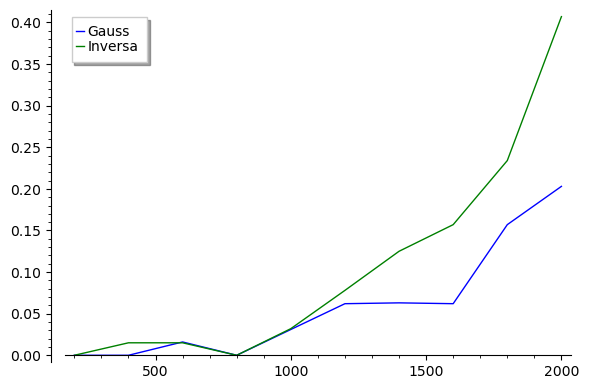

In [44]:
gauss_vs_inv()

In [158]:
A = matrix(RDF,[[40, 35], [0.95, 0.49]])
b = vector(RDF,[5000,100])

P,L,U=A.change_ring(RDF).LU()

solucion=U.solve_right(L.solve_right(P*b))

print(solucion)

(76.92307692307693, 54.945054945054935)


In [84]:
A.is_symmetric()

False

In [86]:
A.is_positive_definite()

True

In [90]:
A.eigenvalues()

[40.824359197992536, -0.3343591979925362]

In [206]:
B = matrix(RDF,[[40, 35], [0.95,0.49]])
#adapta el problema para que se pueda resolver con el metodo de Cholesky y de los mismo resultados que el metodo de Gauss
B = B.transpose()*B
print(B)

[1600.9025 1400.4655]
[1400.4655 1225.2401]


In [124]:
B.is_symmetric()

True

In [125]:
B.is_positive_definite()

True

In [193]:
R=B.cholesky()
#consigue los valores 76.93 y  54.93 con la matriz R
print(R)
#print(R\B*R)

[  40.01127965961599                 0.0]
[   35.0017672994726 0.34115379753252967]


In [266]:
B=A
#print(B)
#print(B.transpose())
#C=matrix([[40, 0.95], [35, 0.49]]) * matrix([[40, 35], [0.95, 0.49]])
MATR_adaptadaChol=matrix(RDF,[[0.8,0.2],[0.2,0.8]])
print(MATR_adaptadaChol.is_positive_definite())
print(MATR_adaptadaChol.is_symmetric())
matr_chol=MATR_adaptadaChol.cholesky()
print(matr_chol)
#print(MATR_adpatadaChol\b*MATR_adpatadaChol)


True
True
[0.8944271909999159                0.0]
[ 0.223606797749979 0.8660254037844386]


In [276]:
#creo una matriz con los coeficientes de las variables
A = matrix(RDF,[[40, 35], [0.95, 0.49]])
#creo una matriz con los resultados de las ecuaciones
b = vector(RDF,[5000,100])

#Operación incorporada en sage que resuelve el sistema de ecuaciones mediante Gauss
print(A\b)


(76.92307692307693, 54.945054945054935)


In [303]:
# Comprobación para chomesky

#1 - Comprobación de que la matriz es simétrica
condicion_simetrica = A.is_symmetric()
print("La matriz es simétrica: ", condicion_simetrica)

#2 - Comprobación de que la matriz es definida positiva
condicion_definidaPositiva = A.is_positive_definite()
print("La matriz es positiva definida: ", condicion_definidaPositiva)

# Se comprueba que la matriz es simétrica y definida positiva
compatibleCholesky = condicion_simetrica and condicion_definidaPositiva
print("La matriz es compatible con el método de Cholesky: ", compatibleCholesky)

def comprobarCholesky(matriz):
    #1 - Comprobación de que la matriz es simétrica
    condicion_simetrica = matriz.is_symmetric()
    #print("La matriz es simétrica: ", condicion_simetrica)

    #2 - Comprobación de que la matriz es definida positiva
    condicion_definidaPositiva = matriz.is_positive_definite()
    #print("La matriz es positiva definida: ", condicion_definidaPositiva)

    # Se comprueba que la matriz es simétrica y definida positiva
    compatibleCholesky = condicion_simetrica and condicion_definidaPositiva
    #print("La matriz es compatible con el método de Cholesky: ", compatibleCholesky)
    return compatibleCholesky#,"La matriz es simétrica: ", condicion_simetrica,"La matriz es positiva definida: ", condicion_definidaPositiva

La matriz es simétrica:  False
La matriz es positiva definida:  True
La matriz es compatible con el método de Cholesky:  False


In [304]:
comprobarCholesky(matrix(RDF,[[0.9,0.7],[0.7,0.9]]))

True

In [289]:
P,L,U=A.LU()
print(U\(L\(P*b)))

(76.92307692307693, 54.945054945054935)


In [326]:

r = b-A*x
print(r)

(9.094947017729282e-13, 1.4210854715202004e-14)


In [325]:
x=A^-1*b